In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# 08 - Research visualisation
Publication-quality figures exported to `report/figures/` and interactive Plotly views.

In [2]:
summ = load_summary(); res = pd.DataFrame(summ['models']['results']).T.reset_index(names='model')
fig = px.bar(res.melt('model', ['precision', 'recall', 'f1', 'roc_auc', 'pr_auc'], 'metric', 'value'), x='model', y='value', color='metric', barmode='group', title='Model comparison (test set)'); fig

In [3]:
tx = summ['transactions']; hr = pd.Series(tx['fraud_rate_by_hour']).rename_axis('hour').reset_index(name='rate')
px.bar(hr, x='hour', y='rate', title='Fraud rate by hour of day')

In [4]:
ev = load_events(); ev['timestamp'] = pd.to_datetime(ev.timestamp)
px.histogram(ev[ev.is_attack == 1], x='timestamp', color='event_type', nbins=90, title='Attack events over time (campaign bursts)')

In [5]:
sc = load_trust(); sv = load_survey()
full = sv.merge(sc[['respondent_id', 'trust_score']], on='respondent_id')
px.box(full, x='age_band', y='trust_score', color='experienced_fraud', category_orders={'age_band': ['18-24', '25-34', '35-44', '45-54', '55+']}, title='Trust by age band and past fraud experience')

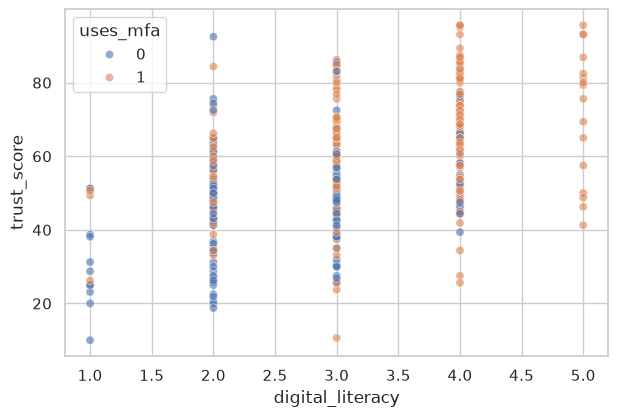

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5)); sns.scatterplot(data=full, x='digital_literacy', y='trust_score', hue='uses_mfa', alpha=.6, ax=ax)
fig.savefig(ROOT / 'report' / 'figures' / 'trust_vs_literacy.png', dpi=140, bbox_inches='tight')

In [7]:
import os; print(sorted(os.listdir(ROOT / 'report' / 'figures')))

['.gitkeep', 'confusion_matrices.png', 'consumer_trust_overview.png', 'model_comparison.html', 'roc_pr_curves.png', 'security_overview.png', 'transaction_overview.png', 'trust_by_age.png', 'trust_vs_literacy.png']
